In [1]:
!pip install blitz-bayesian-pytorch

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 48.4/48.4 kB 1.6 MB/s eta 0:00:00


In [2]:
import warnings
warnings.filterwarnings('ignore')

In [3]:
import matplotlib.pyplot as plt
import math
import pickle
import numpy as np
import torch
import torch.nn as nn
import pandas as pd
import seaborn as sns
import torch.optim as optim
import torch.nn.functional as F
import torch.nn as nn
import json
from blitz.modules import BayesianLinear
from blitz.utils import variational_estimator
from torch.utils.data import TensorDataset, DataLoader
from matplotlib.pyplot import scatter, figure
from scipy import stats
from numpy.ma.core import outer
from sys import stderr

In [4]:
start = -np.pi/2
end = np.pi/2
n = 300
batch_size = 16
modelSamples = 50

In [5]:
# Define the Ishigami function
def ishigami_function(x1, x2, x3, a=7, b=0.1):
    return np.sin(x1) + a * np.sin(x2)**2 + b * x3**4 * np.sin(x1)

# Generate Ishigami dataset with added variance
def generate_ishigami_dataset(start, end, n_samples):
    np.random.seed(0)
    x1 = np.random.uniform(start, end, n_samples)
    x2 = np.random.uniform(start, end, n_samples)
    x3 = np.random.uniform(start, end, n_samples)
    f_x = ishigami_function(x1, x2, x3)
    # Add variance to y
    y_var = 0.2
    y = np.random.normal(f_x, y_var, n_samples)
    return x1, x2, x3, y



In [6]:
x1, x2, x3, y = generate_ishigami_dataset(start, end, n)

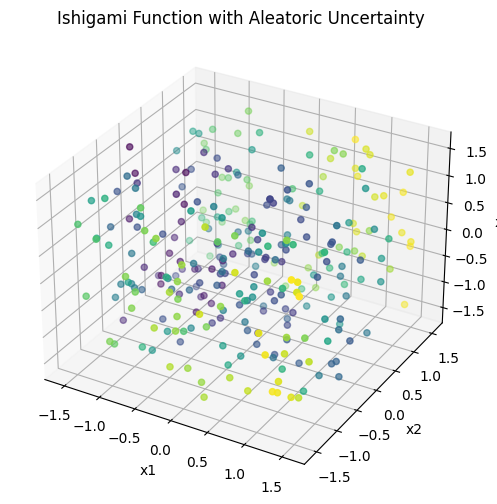

In [7]:
fig = plt.figure(figsize=(10, 6))
ax = fig.add_subplot(111, projection='3d')
ax.scatter(x1, x2, x3, c=y, cmap='viridis')
ax.set_xlabel('x1')
ax.set_ylabel('x2')
ax.set_zlabel('x3')
ax.set_title('Ishigami Function with Aleatoric Uncertainty')
plt.show()

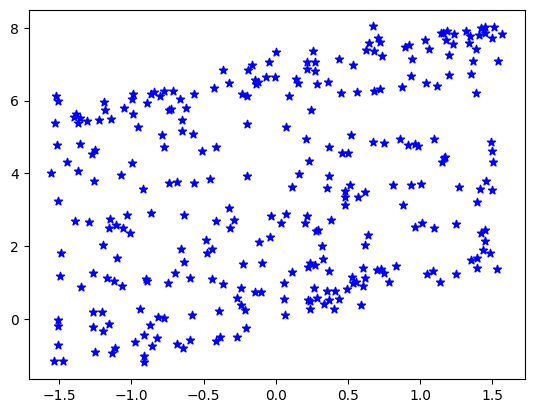

In [8]:
x1_train, y_train = x1,y
scatter(x1_train, y_train, c="blue", marker="*")

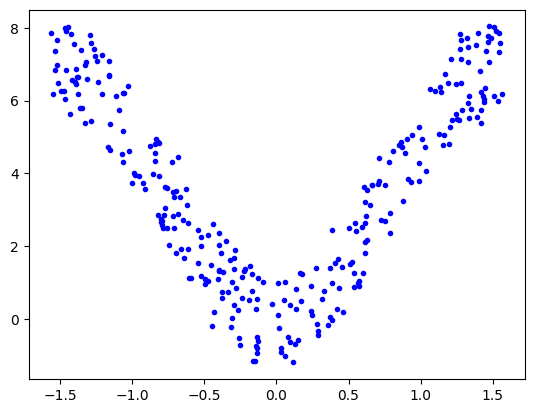

In [9]:
x2_train, y_train = x2,y
scatter(x2_train, y_train, c="blue", marker=".")

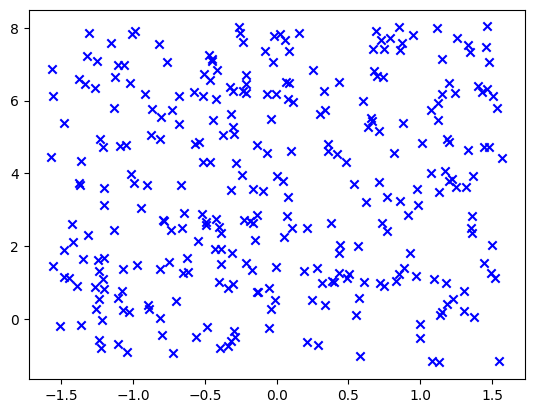

In [10]:
x3_train, y_train = x3,y
scatter(x3_train, y_train, c="blue", marker="x")

In [11]:
figure(figsize=(4, 4))
# Not exactely the same distribution, but works for now
x1_test, x2_test,x3_test, y_test = generate_ishigami_dataset(-np.pi, np.pi, 200)

<Figure size 400x400 with 0 Axes>

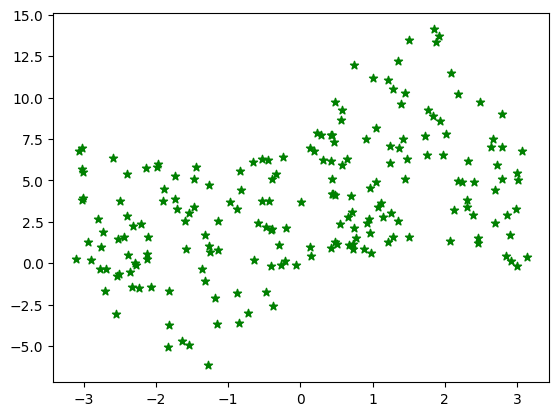

In [12]:
scatter(x1_test, y_test, c="green", marker="*")

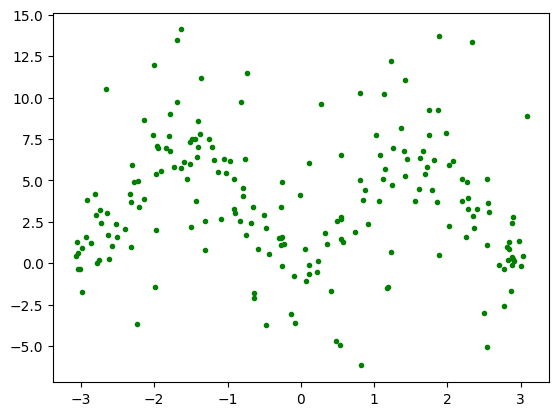

In [13]:
scatter(x2_test, y_test, c="green", marker=".")

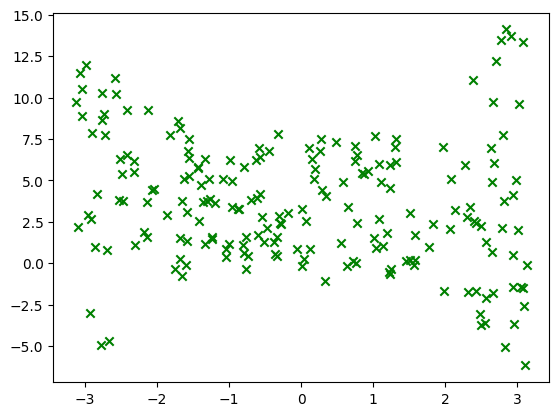

In [14]:
scatter(x3_test, y_test, c="green", marker="x")

In [15]:
# #Plotting In Training Distribution Data Points in the Test Set
# # Filter the data to retain only the desired ranges
# mask_x1_test_idd =  (x1_test >= start) &  (x1_test <= end) # Select the ranges -pi/2 to pi/2
# x1_test_idd = x1_test[mask_x1_test_idd]
# y_test_idd = y_test[mask_x1_test_idd]

# plt.figure(figsize=(4, 4))
# plt.scatter(x1_test_idd, y_test_idd, c="yellow", marker="*")

# plt.show()


In [16]:
# mask_x2_test_idd =  (x2_test >= start) &  (x2_test <= end) # Select the ranges -pi/2 to pi/2
# x2_test_idd = x2_test[mask_x2_test_idd]
# y_test_idd = y_test[mask_x2_test_idd]

# plt.figure(figsize=(4, 4))
# plt.scatter(x2_test_idd, y_test_idd, c="yellow", marker=".")

# plt.show()

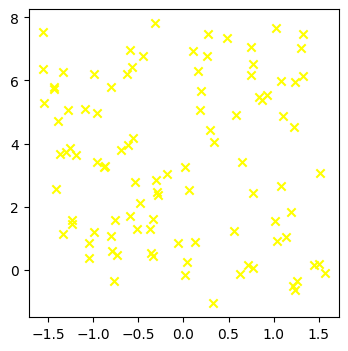

In [17]:
mask_x3_test_idd =  (x3_test >= start) &  (x3_test <= end) # Select the ranges -pi/2 to pi/2
x3_test_idd = x3_test[mask_x3_test_idd]
y_test_idd = y_test[mask_x3_test_idd]

plt.figure(figsize=(4, 4))
plt.scatter(x3_test_idd, y_test_idd, c="yellow", marker="x")

plt.show()

In [18]:
# #Plotting Out of Training Distribution Data Points in the Test Set
# # Filter the data to retain only the desired ranges
# mask_x1_test_oodd = (x1_test >= -np.pi) & (x1_test < start) | (x1_test > end) & (x1_test <= np.pi) # Select the ranges -pi to -pi/2 and pi/2 to pi
# x1_test_oodd = x1_test[mask_x1_test_oodd]
# y_test_oodd = y_test[mask_x1_test_oodd]

# plt.figure(figsize=(4, 4))
# plt.scatter(x1_test_oodd, y_test_oodd, c="red", marker="*")

# plt.show()


In [19]:
# mask_x2_test_oodd = (x2_test >= -np.pi) & (x2_test < start) | (x2_test > end) & (x2_test <= np.pi) # Select the ranges -pi to -pi/2 and pi/2 to pi
# x2_test_oodd = x2_test[mask_x2_test_oodd]
# y_test_oodd = y_test[mask_x2_test_oodd]

# plt.figure(figsize=(4, 4))
# plt.scatter(x2_test_oodd, y_test_oodd, c="red", marker=".")

# plt.show()

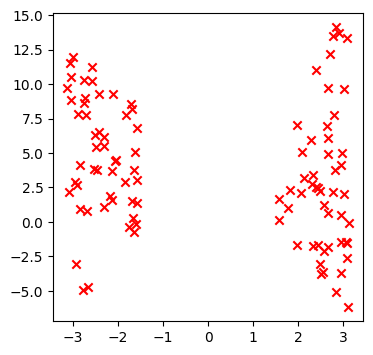

In [20]:
mask_x3_test_oodd = (x3_test >= -np.pi) & (x3_test < start) | (x3_test > end) & (x3_test <= np.pi) # Select the ranges -pi to -pi/2 and pi/2 to pi
x3_test_oodd = x3_test[mask_x3_test_oodd]
y_test_oodd = y_test[mask_x3_test_oodd]

plt.figure(figsize=(4, 4))
plt.scatter(x3_test_oodd, y_test_oodd, c="red", marker="x")

plt.show()

In [21]:


# Train
tensor_x = torch.Tensor(x3_train).unsqueeze(1)
tensor_y = torch.Tensor(y_train).unsqueeze(1)
train_dataset = TensorDataset(tensor_x, tensor_y)
train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)

#Test for OODD (Out of Data Distribution)
tensor_x_test_oodd = torch.Tensor(x3_test_oodd).unsqueeze(1)
tensor_y_test_oodd = torch.Tensor(y_test_oodd).unsqueeze(1)
test_dataset_oodd = TensorDataset(tensor_x_test_oodd, tensor_y_test_oodd)
test_loader_oodd = DataLoader(test_dataset_oodd, batch_size=batch_size, shuffle=True)

# #Test for IDD (In Data Distribution)
tensor_x_test_idd = torch.Tensor(x3_test_idd).unsqueeze(1)
tensor_y_test_idd = torch.Tensor(y_test_idd).unsqueeze(1)
test_dataset_idd = TensorDataset(tensor_x_test_idd, tensor_y_test_idd)
test_loader_idd = DataLoader(test_dataset_idd, batch_size=batch_size, shuffle=True)

# Test
tensor_x_test = torch.Tensor(x3_test).unsqueeze(1)
tensor_y_test = torch.Tensor(y_test).unsqueeze(1)
test_dataset = TensorDataset(tensor_x_test, tensor_y_test)
test_loader = DataLoader(test_dataset, batch_size=batch_size, shuffle=True)

In [22]:
@variational_estimator
class BayesianNetwork(nn.Module):
    def __init__(self):
        super().__init__()
        hidden_size = 29
        self.blinear1 = BayesianLinear(1, hidden_size, prior_sigma_1=1)
        self.blinear2 = BayesianLinear(hidden_size, hidden_size, prior_sigma_1=1)
        self.blinear3 = BayesianLinear(hidden_size, 1, prior_sigma_1=1)

    def forward(self, x):
        x_ = torch.relu(self.blinear1(x))
        x_ = torch.relu(self.blinear2(x_))
        return self.blinear3(x_)

In [23]:

def plot_with_confidence_interval(model, tensor_x_test, tensor_y_test, x_test,y_test,color,start, end):
    samples = 500
    preds = [model(tensor_x_test) for i in range(samples)]
    preds = torch.stack(preds)
    means = preds.mean(axis=0).detach().numpy()
    stds =  preds.std(axis=0).detach().numpy()
    mu = means
    sigma = stds
    # Calculate the 95% confidence interval
    lower_bound = mu - 2 * sigma
    upper_bound = mu + 2 * sigma

    # Count the data points within the confidence interval
    count_within_ci = np.sum((tensor_y_test.numpy() >= lower_bound) & (tensor_y_test.numpy() <= upper_bound))
    percentage_count_within_ci = (count_within_ci / tensor_y_test.shape[0]) * 100
    print(f'Number of data points within the 95% confidence interval: {count_within_ci}')
    print(f'Percentage of data points within the 95% confidence interval: {percentage_count_within_ci}')

    # ~ 95% conf. interval (see https://en.wikipedia.org/wiki/1.96)
    y_vals = [mu, mu + 2 * sigma, mu - 2 * sigma]
    dfs = []

    # Create DF from predictions
    for i in range(3):
        data = {
            "x": list(tensor_x_test.squeeze().numpy()),
            "y": list(y_vals[i].squeeze())
        }
        temp = pd.DataFrame.from_dict(data)
        dfs.append(temp)
    df = pd.concat(dfs).reset_index()

    # Plot predictions with confidence
    sns.set(rc={'figure.figsize': (4, 4)})
    sns_plot = sns.lineplot(data=df, x="x", y="y")

    # Highlight training range
    plt.axvline(x=start)
    plt.axvline(x=end)

    # Plot test data on top
    scatter(x_test, y_test, c=color, marker="*", alpha=1.0)
    plt.show()
    return percentage_count_within_ci


In [24]:
def train_and_evaluate_net(net, train_loader, test_loader, tensor_x_test, tensor_y_test,  x_test, y_test, color, test_dataset,num_epochs=150, learning_rate=0.001):
    # Define loss and optimizer
    device = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")
    criterion = torch.nn.MSELoss()
    optimizer = optim.Adam(net.parameters(), lr=learning_rate)
    net.train()
    net.to(device)

    for epoch in range(num_epochs):
        # Train loop
        for batch in train_loader:
            x, y = batch[0].to(device), batch[1].to(device)
            optimizer.zero_grad()
            loss = net.sample_elbo(inputs=x,
                           labels=y,
                           criterion=criterion,
                           sample_nbr=1,
                           complexity_cost_weight=0.01/len(train_dataset))
            loss.backward()
            optimizer.step()

        if epoch % 10 == 0:
            all_test_losses = []

            # Test loop
            for batch in test_loader:
                x, y = batch[0].to(device), batch[1].to(device)
                loss = net.sample_elbo(inputs=x,
                           labels=y,
                           criterion=criterion,
                           sample_nbr=3,
                           complexity_cost_weight=0.01/len(test_dataset))
                all_test_losses.append(loss.item())
            test_loss = sum(all_test_losses) / len(all_test_losses)

    percentage_count_within_ci=plot_with_confidence_interval(net, tensor_x_test, tensor_y_test,x_test,y_test,color,start, end)
    return loss, test_loss,net,percentage_count_within_ci

def Neural_Network(net,train_loader,test_loader,tensor_x_test,tensor_y_test, x_test,y_test,color,tst_dtast):
    train_loss, test_loss,net,percentage_count_within_ci = train_and_evaluate_net(net, train_loader, test_loader,tensor_x_test,tensor_y_test, x_test,y_test,color,tst_dtast)
    return train_loss, test_loss,net,percentage_count_within_ci



In [25]:

# Example JSON string
json_str = '''
{
  "test_loaders": ["test_loader", "test_loader_oodd", "test_loader_idd"],
  "test_tensors_x":["tensor_x_test","tensor_x_test_oodd","tensor_x_test_idd"],
  "test_tensors_y":["tensor_y_test","tensor_y_test_oodd","tensor_y_test_idd"],
  "test_datasets":["test_dataset","test_dataset_oodd","test_dataset_idd"],
  "color":["green","red","yellow"],
  "testset_x":["x_test","x_test_oodd","x_test_idd"],
  "testset_y":["y_test","y_test_oodd","y_test_idd"],
  "output_dirs": ["pickled_models_", "pickled_models_oodd_", "pickled_models_idd_"],
  "error_metrics":["em","em_oodd","em_idd"]
}
'''

# Parse JSON
data = json.loads(json_str)

# Map string names to actual variables
test_loader_vars = {
    "test_loader": test_loader,
    "test_loader_oodd": test_loader_oodd,
    "test_loader_idd": test_loader_idd
}
tensor_x_mapping = {
    "tensor_x_test": tensor_x_test,
    "tensor_x_test_oodd": tensor_x_test_oodd,
    "tensor_x_test_idd": tensor_x_test_idd
}

tensor_y_mapping = {
    "tensor_y_test": tensor_y_test,
    "tensor_y_test_oodd": tensor_y_test_oodd,
    "tensor_y_test_idd": tensor_y_test_idd
}
testset_x_mapping = {
    "x_test": x3_test,
    "x_test_oodd": x3_test_oodd,
    "x_test_idd": x3_test_idd
}

# Mapping from string names to actual variables for testset_y
testset_y_mapping = {
    "y_test": y_test,
    "y_test_oodd": y_test_oodd,
    "y_test_idd": y_test_idd
}
test_datasets_mapping = {
    "test_dataset": test_dataset,
    "test_dataset_oodd": test_dataset_oodd,
    "test_dataset_idd": test_dataset_idd
}
# Access corresponding values using a loop
test_loaders = data["test_loaders"]
test_tensors_x=data["test_tensors_x"]
test_tensors_y=data["test_tensors_y"]
test_datasets=data["test_datasets"]
color=data["color"]
testset_x=data["testset_x"]
testset_y=data["testset_y"]
output_dirs = data["output_dirs"]
error_mets=data["error_metrics"]



Number of data points within the 95% confidence interval: 0
Percentage of data points within the 95% confidence interval: 0.0


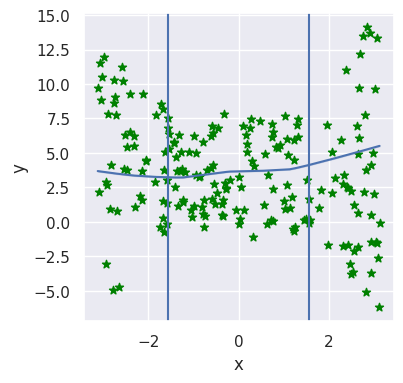

Number of data points within the 95% confidence interval: 0
Percentage of data points within the 95% confidence interval: 0.0


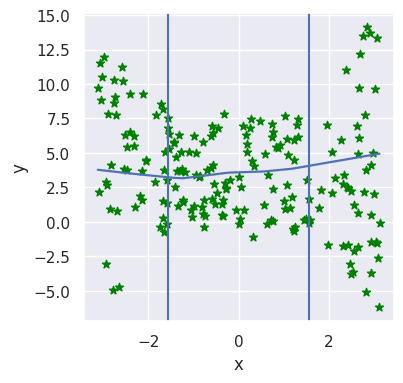

Number of data points within the 95% confidence interval: 0
Percentage of data points within the 95% confidence interval: 0.0


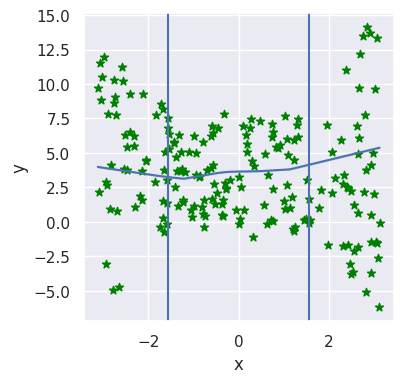

Number of data points within the 95% confidence interval: 0
Percentage of data points within the 95% confidence interval: 0.0


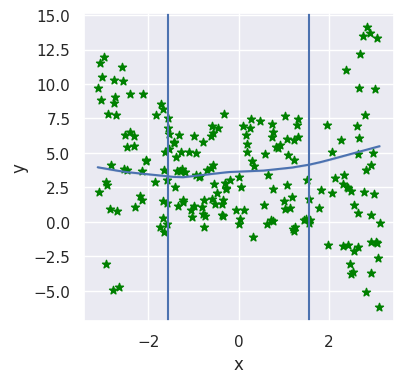

Number of data points within the 95% confidence interval: 0
Percentage of data points within the 95% confidence interval: 0.0


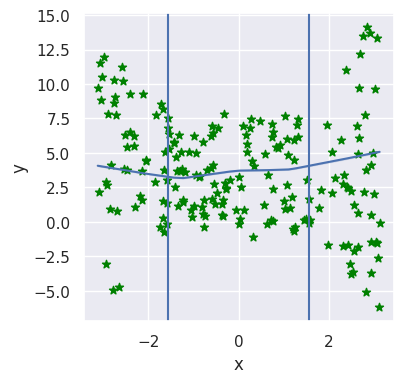

Number of data points within the 95% confidence interval: 0
Percentage of data points within the 95% confidence interval: 0.0


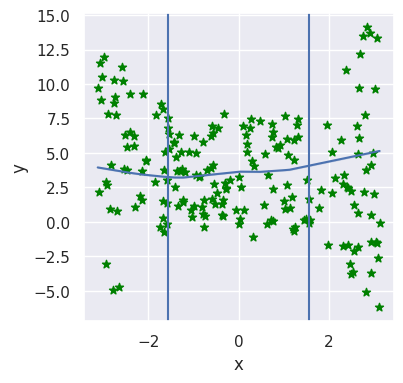

Number of data points within the 95% confidence interval: 0
Percentage of data points within the 95% confidence interval: 0.0


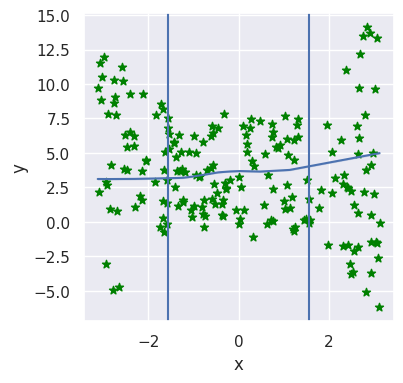

Number of data points within the 95% confidence interval: 1
Percentage of data points within the 95% confidence interval: 0.5


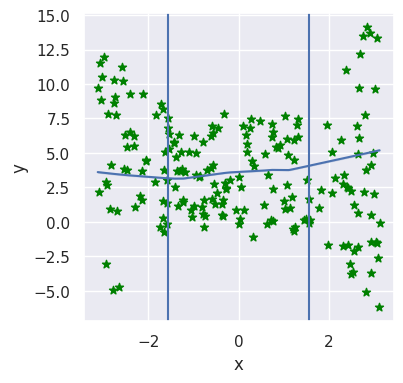

Number of data points within the 95% confidence interval: 0
Percentage of data points within the 95% confidence interval: 0.0


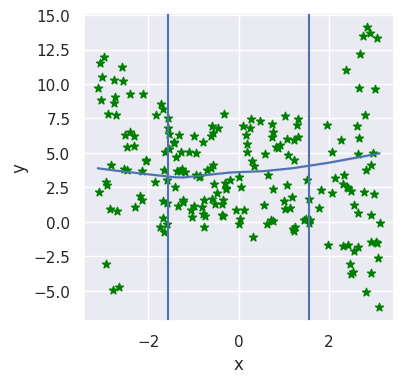

Number of data points within the 95% confidence interval: 0
Percentage of data points within the 95% confidence interval: 0.0


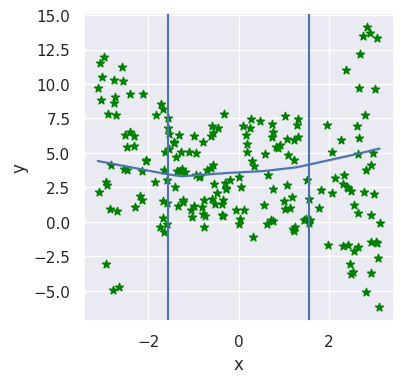

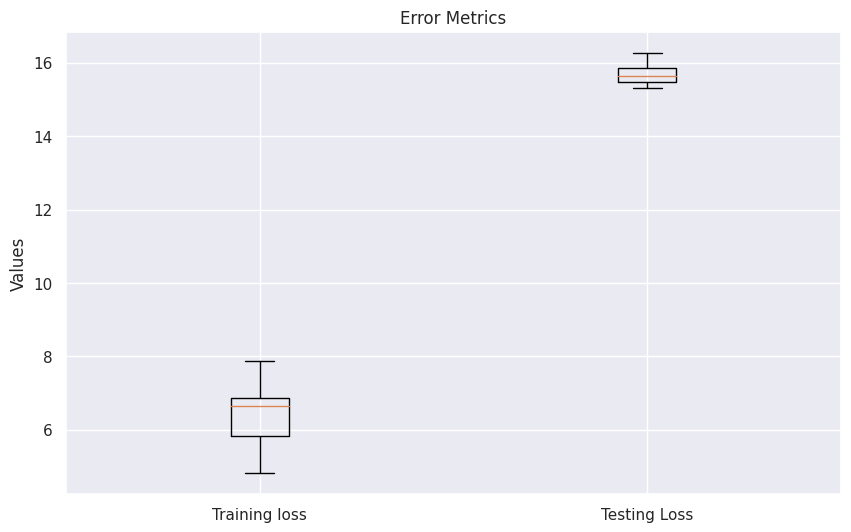

    Training Loss  Testing Loss  % of points in Confidence Interval
1        7.192184     16.257383                                 0.0
2        6.716095     15.299444                                 0.0
3        6.069343     15.904282                                 0.0
4        6.826924     15.514830                                 0.0
5        7.870909     15.701205                                 0.0
6        6.878980     15.459104                                 0.0
7        5.085773     16.271608                                 0.0
8        5.750899     15.600912                                 0.5
9        4.831203     15.752462                                 0.0
10       6.568932     15.373015                                 0.0
Mean of Gausiann Training Loss of 10 runs  6.379124116897583
Standard Deviation of Gausiann Training Loss of 10 runs  0.8969892812158328
Mean of Gausiann Testing Loss of 10 runs  15.713424414854781
Standard Deviation of Gausiann Testing Loss of 10 runs

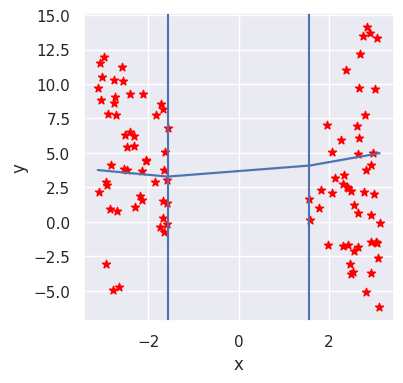

Number of data points within the 95% confidence interval: 0
Percentage of data points within the 95% confidence interval: 0.0


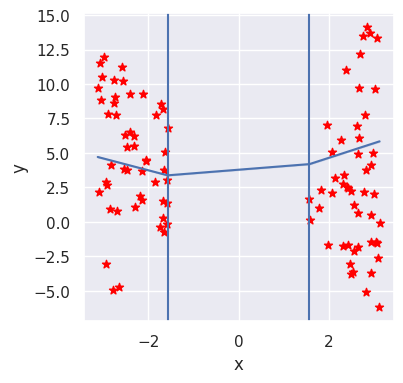

Number of data points within the 95% confidence interval: 0
Percentage of data points within the 95% confidence interval: 0.0


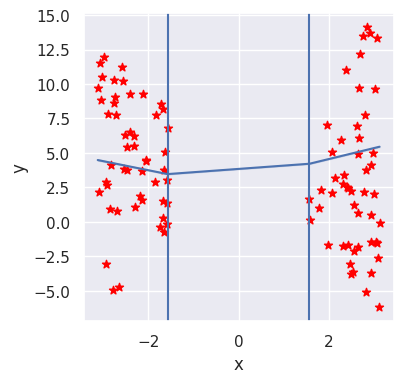

Number of data points within the 95% confidence interval: 0
Percentage of data points within the 95% confidence interval: 0.0


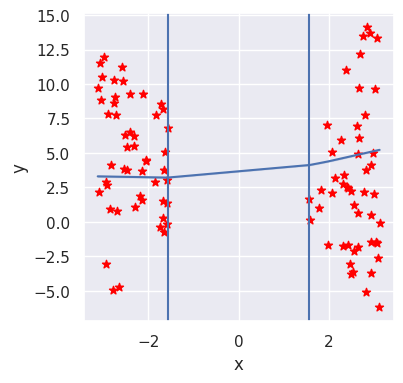

Number of data points within the 95% confidence interval: 2
Percentage of data points within the 95% confidence interval: 2.0


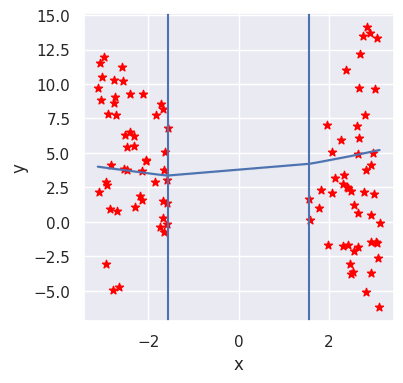

Number of data points within the 95% confidence interval: 0
Percentage of data points within the 95% confidence interval: 0.0


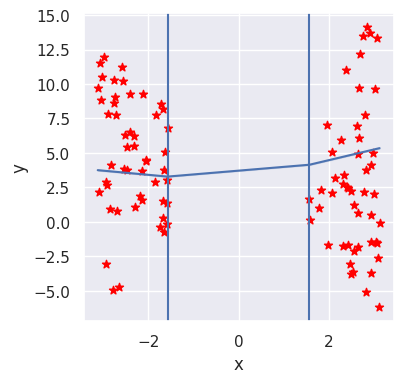

Number of data points within the 95% confidence interval: 1
Percentage of data points within the 95% confidence interval: 1.0


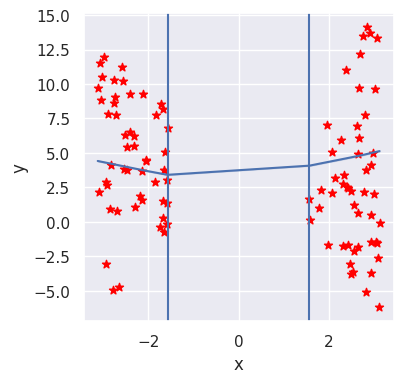

Number of data points within the 95% confidence interval: 1
Percentage of data points within the 95% confidence interval: 1.0


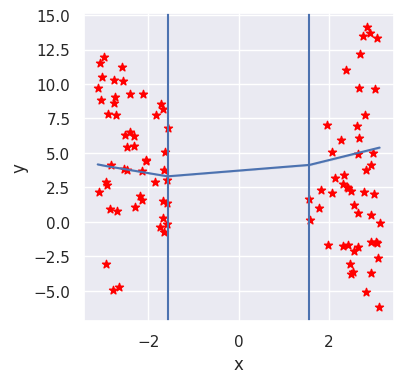

Number of data points within the 95% confidence interval: 1
Percentage of data points within the 95% confidence interval: 1.0


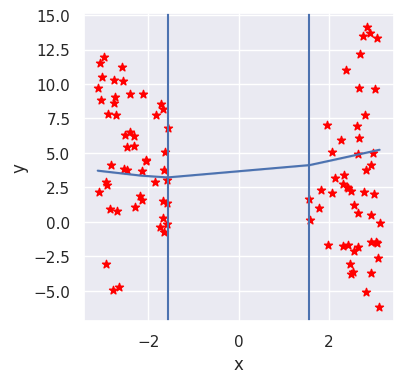

Number of data points within the 95% confidence interval: 0
Percentage of data points within the 95% confidence interval: 0.0


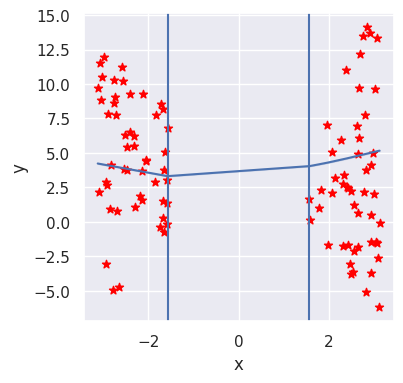

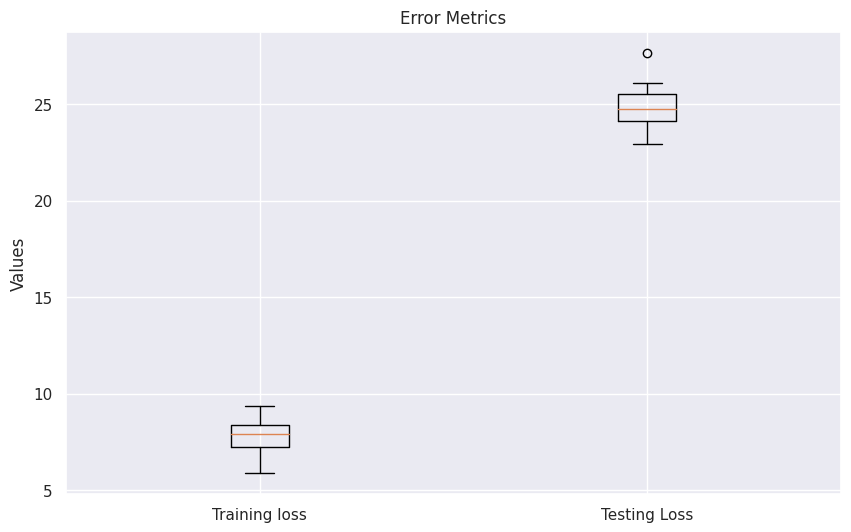

    Training Loss  Testing Loss  % of points in Confidence Interval
1        7.958387     24.084630                                 0.0
2        7.030619     24.336791                                 0.0
3        8.267168     25.219596                                 0.0
4        7.082712     25.615498                                 0.0
5        7.764489     24.382991                                 2.0
6        9.158781     25.118365                                 0.0
7        7.888896     22.951958                                 1.0
8        9.383570     23.854478                                 1.0
9        8.428268     27.677312                                 1.0
10       5.905103     26.099789                                 0.0
Mean of Gausiann Training Loss of 10 runs  7.8867991924285885
Standard Deviation of Gausiann Training Loss of 10 runs  0.980965860940265
Mean of Gausiann Testing Loss of 10 runs  24.934140716280258
Standard Deviation of Gausiann Testing Loss of 10 runs

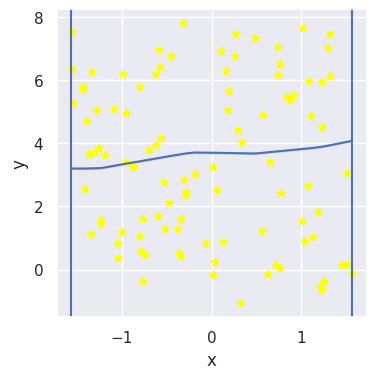

Number of data points within the 95% confidence interval: 0
Percentage of data points within the 95% confidence interval: 0.0


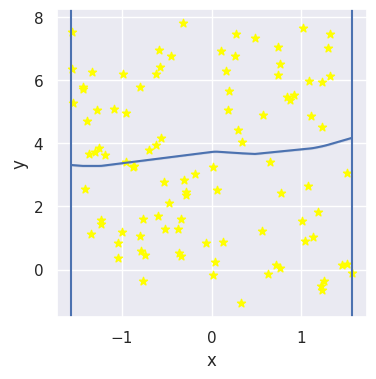

Number of data points within the 95% confidence interval: 0
Percentage of data points within the 95% confidence interval: 0.0


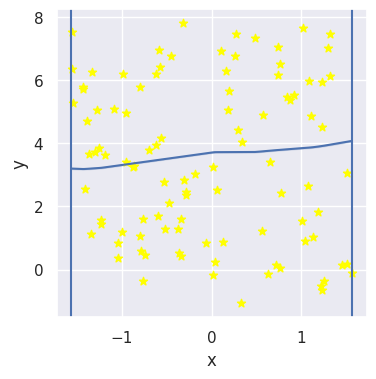

Number of data points within the 95% confidence interval: 0
Percentage of data points within the 95% confidence interval: 0.0


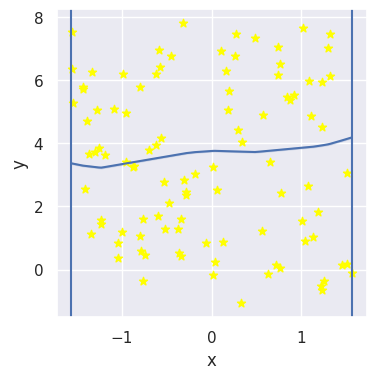

Number of data points within the 95% confidence interval: 0
Percentage of data points within the 95% confidence interval: 0.0


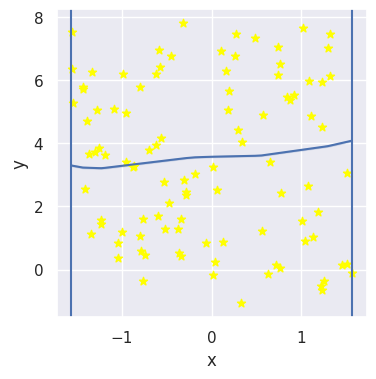

Number of data points within the 95% confidence interval: 0
Percentage of data points within the 95% confidence interval: 0.0


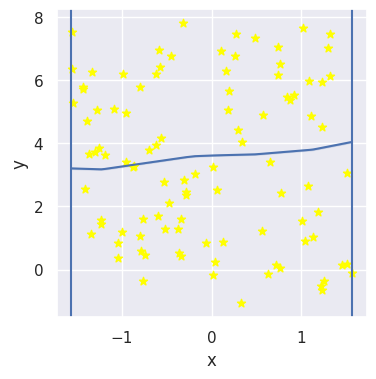

Number of data points within the 95% confidence interval: 0
Percentage of data points within the 95% confidence interval: 0.0


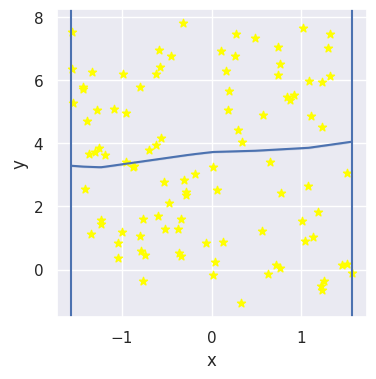

Number of data points within the 95% confidence interval: 0
Percentage of data points within the 95% confidence interval: 0.0


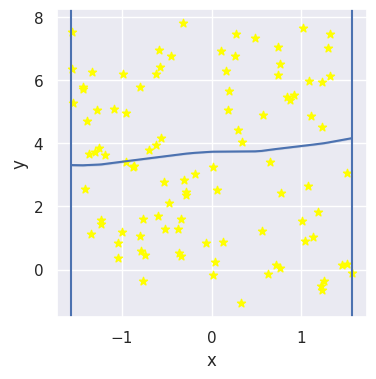

Number of data points within the 95% confidence interval: 0
Percentage of data points within the 95% confidence interval: 0.0


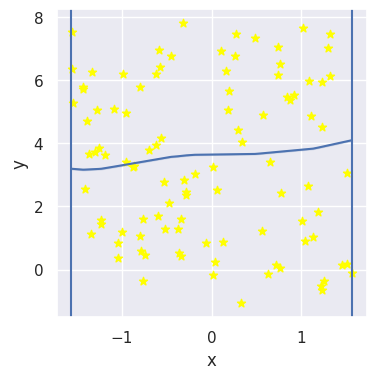

Number of data points within the 95% confidence interval: 0
Percentage of data points within the 95% confidence interval: 0.0


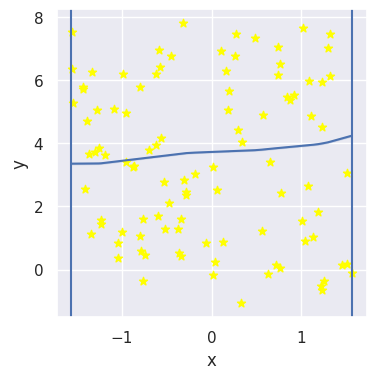

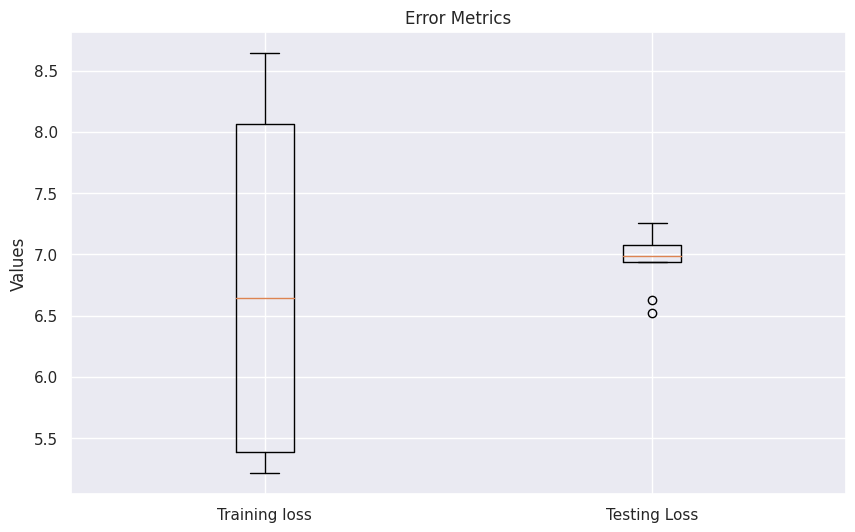

    Training Loss  Testing Loss  % of points in Confidence Interval
1        5.470191      7.222085                                 0.0
2        6.050687      7.259859                                 0.0
3        5.362773      6.625900                                 0.0
4        8.645272      6.943252                                 0.0
5        5.295163      6.999807                                 0.0
6        8.345757      6.980666                                 0.0
7        8.223834      7.082701                                 0.0
8        5.217384      6.520401                                 0.0
9        7.239868      7.052729                                 0.0
10       7.598018      6.935359                                 0.0
Mean of Gausiann Training Loss of 10 runs  6.744894790649414
Standard Deviation of Gausiann Training Loss of 10 runs  1.333654327831838
Mean of Gausiann Testing Loss of 10 runs  6.962276015962874
Standard Deviation of Gausiann Testing Loss of 10 runs  

In [26]:
for tst_loader,tnsor_x_test,tnsor_y_test, col, x_test,y_test,output_dir, error_metric,tst_dtast in zip(test_loaders,test_tensors_x,test_tensors_y,color,testset_x,testset_y,output_dirs,error_mets,test_datasets):
  train_losses=[]
  test_losses=[]
  percentages_count_within_ci=[]
  for i in range(10):
    net=BayesianNetwork()
    tr_loss,test_loss,model,percentage_count_within_ci = Neural_Network(net,train_loader,test_loader_vars[tst_loader],tensor_x_mapping[tnsor_x_test],tensor_y_mapping[tnsor_y_test],testset_x_mapping[x_test],testset_y_mapping[y_test],col,test_datasets_mapping[tst_dtast])
    error_metrics=tr_loss,test_loss,model,percentage_count_within_ci
    model_filename = f"{output_dir}model_{i}.pkl"
    with open(model_filename, 'wb') as file:
      pickle.dump(error_metrics, file)
    train_losses.append(tr_loss)
    test_losses.append(test_loss)

    percentages_count_within_ci.append(percentage_count_within_ci)
  # Extract numerical values from the tensors and remove grad_fn
  tr_loss_values= [tensor.item() for tensor in train_losses]
  test_loss_values=test_losses

  # Create a figure and axis
  fig, ax = plt.subplots(figsize=(10, 6))
  # Create box plots for each dataset
  box_plot_data = [tr_loss_values, test_loss_values]
  box_labels = ['Training loss', 'Testing Loss']
  ax.boxplot(box_plot_data, labels=box_labels)
  # Add labels and title
  ax.set_ylabel('Values')
  ax.set_title('Error Metrics')
  plt.savefig(f'bnn_arch_{error_metric}.png', dpi=300)
  # Show the plot
  plt.show()

  mean_gaus_train_loss = np.mean(tr_loss_values)
  std_dev_gaus_train_loss = np.std(tr_loss_values)

  mean_gaus_test_loss = np.mean(test_loss_values)
  std_dev_gaus_test_loss = np.std(test_loss_values)

  mean_percentages_count_within_ci = np.mean(percentages_count_within_ci)
  std_dev_percentages_count_within_ci = np.std(percentages_count_within_ci)

  # Create a DataFrame from the lists
  data = {
    'Training Loss': tr_loss_values,
    'Testing Loss': test_loss_values,
    '% of points in Confidence Interval':percentages_count_within_ci,
  }

  num_columns = len(data)

  column_names = ['Training Loss','Testing Loss','% of points in Confidence Interval']
  # Create a DataFrame with dynamic column names
  df = pd.DataFrame(data, columns=column_names)
  df.index += 1
  # Display the DataFrame as a table
  print(df)
  df.to_csv(f'bnn_results_{error_metric}.txt', index=True)
  print('Mean of Gausiann Training Loss of 10 runs ', mean_gaus_train_loss)
  print('Standard Deviation of Gausiann Training Loss of 10 runs ' , std_dev_gaus_train_loss )

  print('Mean of Gausiann Testing Loss of 10 runs ',mean_gaus_test_loss )
  print('Standard Deviation of Gausiann Testing Loss of 10 runs ',std_dev_gaus_test_loss)

  print('Mean of percentage of 95% conf interval for 10 runs in data',mean_percentages_count_within_ci)
  print('Standard Deviation of percentage of 95% conf interval for 10 runs in data ' , std_dev_percentages_count_within_ci)

  # File path
  file_path = f'bnn_summary_{error_metric}.txt'

  # Open the file in write mode
  with open(file_path, 'w') as file:
    # Write the results to the file
    file.write('Mean of Gaussian Training Loss of 10 runs: {}\n'.format(mean_gaus_train_loss))
    file.write('Standard Deviation of Gaussian Training Loss of 10 runs: {}\n\n'.format(std_dev_gaus_train_loss))

    file.write('Mean of Gaussian Testing Loss of 10 runs: {}\n'.format(mean_gaus_test_loss))
    file.write('Standard Deviation of Gaussian Testing Loss of 10 runs: {}\n\n'.format(std_dev_gaus_test_loss))

    file.write('Mean of percentage of 95% conf interval for 10 runs in data {}\n'.format(mean_percentages_count_within_ci))
    file.write('Standard Deviation of percentage of 95% conf interval for 10 runs in data {}\n\n'.format(std_dev_percentages_count_within_ci))

  # Print a message indicating the file has been saved
  print(f'Results summary saved to {file_path}')
